In [1]:
# Q1. Candidate-Elimination (General & Specific boundaries)
import numpy as np
import pandas as pd

data1 = pd.DataFrame([
    ['Clear','Hot','Low','Light','Warm','Stable','Yes'],
    ['Clear','Warm','Medium','Light','Warm','Stable','Yes'],
    ['Stormy','Cool','High','Gusty','Cold','Changing','No'],
    ['Clear','Hot','Medium','Moderate','Cool','Stable','Yes'],
    ['Hazy','Cool','High','Moderate','Cold','Changing','No'],
    ['Clear','Cool','Low','Gusty','Warm','Stable','No'],
    ['Clear','Warm','Low','Moderate','Warm','Changing','Yes'],
    ['Stormy','Warm','High','Gusty','Cool','Changing','No']],
    columns=['Sky','Temperature','Humidity','Wind','Water','Forecast','Activity'])
print(data1, "\n")

X = data1.iloc[:, :-1].values
y = data1.iloc[:, -1].values
n = X.shape[1]
domains = [sorted(set(X[:, j])) for j in range(n)]

def covers(h, x):                       # does hypothesis h classify x as positive?
    return all(h[j] == '?' or h[j] == x[j] for j in range(len(h)))

def more_general_or_equal(h1, h2):      # is h1 >= h2 ?
    return all(a == '?' or a == b or b == '0' for a, b in zip(h1, h2))

def candidate_elimination(X, y):
    S = ['0'] * n                        # most specific boundary
    G = [['?'] * n]                      # most general boundary
    for i, x in enumerate(X):
        if y[i] == 'Yes':                # ---- positive example
            G = [g for g in G if covers(g, x)]
            for j in range(n):
                if S[j] == '0':
                    S[j] = x[j]
                elif S[j] != x[j]:
                    S[j] = '?'
        else:                            # ---- negative example
            if covers(S, x):
                print(f"After example {i+1} (No):  WARNING - S already covers this negative example,")
                print("   so NO conjunctive hypothesis fits all the data (inconsistent / noisy example).")
                print("   Example skipped so the boundaries stay meaningful.\n")
                continue
            newG = []
            for g in G:
                if not covers(g, x):
                    newG.append(g)
                else:
                    for j in range(n):
                        if g[j] == '?':
                            for val in domains[j]:
                                if val != x[j]:
                                    h = g.copy(); h[j] = val
                                    if more_general_or_equal(h, S):
                                        newG.append(h)
            # remove duplicates and non-maximal hypotheses
            uniq = []
            for h in newG:
                if h not in uniq: uniq.append(h)
            G = [h for h in uniq if not any(o != h and more_general_or_equal(o, h) for o in uniq)]
        print(f"After example {i+1} ({y[i]}):  S = {S}")
        print(f"                       G = {G}\n")
    return S, G

S_final, G_final = candidate_elimination(X, y)
print("Final Specific boundary S:", S_final)
print("Final General boundary G :", G_final)

      Sky Temperature Humidity      Wind Water  Forecast Activity
0   Clear         Hot      Low     Light  Warm    Stable      Yes
1   Clear        Warm   Medium     Light  Warm    Stable      Yes
2  Stormy        Cool     High     Gusty  Cold  Changing       No
3   Clear         Hot   Medium  Moderate  Cool    Stable      Yes
4    Hazy        Cool     High  Moderate  Cold  Changing       No
5   Clear        Cool      Low     Gusty  Warm    Stable       No
6   Clear        Warm      Low  Moderate  Warm  Changing      Yes
7  Stormy        Warm     High     Gusty  Cool  Changing       No 

After example 1 (Yes):  S = ['Clear', 'Hot', 'Low', 'Light', 'Warm', 'Stable']
                       G = [['?', '?', '?', '?', '?', '?']]

After example 2 (Yes):  S = ['Clear', '?', '?', 'Light', 'Warm', 'Stable']
                       G = [['?', '?', '?', '?', '?', '?']]

After example 3 (No):  S = ['Clear', '?', '?', 'Light', 'Warm', 'Stable']
                       G = [['Clear', '?', '?', '?', '

In [2]:
# Q2. FIND-S (most specific hypothesis)
import numpy as np
import pandas as pd

data2 = pd.DataFrame([
    ['HP','i5','8GB','SSD','Integrated','Medium','Yes'],
    ['Dell','i7','16GB','SSD','Dedicated','High','Yes'],
    ['Lenovo','i3','4GB','HDD','Integrated','Low','No'],
    ['HP','i7','16GB','SSD','Dedicated','High','Yes'],
    ['Acer','i3','4GB','HDD','Integrated','Low','No'],
    ['Asus','i5','8GB','SSD','Dedicated','Medium','Yes']],
    columns=['Brand','Processor','RAM','Storage','Graphics','Price','Purchase'])
print(data2, "\n")

attrs = data2.iloc[:, :-1].values
target = data2.iloc[:, -1].values

def find_s(attrs, target):
    h = None
    for x, label in zip(attrs, target):
        if label == 'Yes':                       # negatives are ignored
            if h is None:
                h = list(x)                      # first positive example
            else:
                h = [h[j] if h[j] == x[j] else '?' for j in range(len(h))]
            print("After positive example", list(x), "->", h)
    return h

print("\nMost specific hypothesis:", find_s(attrs, target))

    Brand Processor   RAM Storage    Graphics   Price Purchase
0      HP        i5   8GB     SSD  Integrated  Medium      Yes
1    Dell        i7  16GB     SSD   Dedicated    High      Yes
2  Lenovo        i3   4GB     HDD  Integrated     Low       No
3      HP        i7  16GB     SSD   Dedicated    High      Yes
4    Acer        i3   4GB     HDD  Integrated     Low       No
5    Asus        i5   8GB     SSD   Dedicated  Medium      Yes 

After positive example ['HP', 'i5', '8GB', 'SSD', 'Integrated', 'Medium'] -> ['HP', 'i5', '8GB', 'SSD', 'Integrated', 'Medium']
After positive example ['Dell', 'i7', '16GB', 'SSD', 'Dedicated', 'High'] -> ['?', '?', '?', 'SSD', '?', '?']
After positive example ['HP', 'i7', '16GB', 'SSD', 'Dedicated', 'High'] -> ['?', '?', '?', 'SSD', '?', '?']
After positive example ['Asus', 'i5', '8GB', 'SSD', 'Dedicated', 'Medium'] -> ['?', '?', '?', 'SSD', '?', '?']

Most specific hypothesis: ['?', '?', '?', 'SSD', '?', '?']


In [3]:
# Q3. ID3 Decision Tree (information gain) + prediction
import math
import pandas as pd
from collections import Counter

data3 = pd.DataFrame([
    ['High','Good','Stable','Yes','Yes'],
    ['High','Good','Temporary','No','Yes'],
    ['Medium','Good','Stable','No','Yes'],
    ['Low','Good','Stable','No','Yes'],
    ['Low','Poor','Stable','Yes','No'],
    ['Medium','Poor','Temporary','No','No'],
    ['High','Poor','Temporary','Yes','No'],
    ['Low','Poor','Temporary','No','No'],
    ['Medium','Good','Temporary','Yes','Yes'],
    ['High','Good','Stable','No','Yes'],
    ['Low','Good','Temporary','Yes','Yes'],
    ['Medium','Poor','Stable','No','No']],
    columns=['Income','CreditHistory','Employment','Collateral','Approve'])
print(data3, "\n")

def entropy(labels):
    total = len(labels)
    return -sum((c/total) * math.log2(c/total) for c in Counter(labels).values())

def info_gain(df, attr, target_col):
    total_entropy = entropy(df[target_col])
    weighted = sum((len(sub)/len(df)) * entropy(sub[target_col])
                   for _, sub in df.groupby(attr))
    return total_entropy - weighted

def id3(df, features, target_col):
    labels = df[target_col]
    if labels.nunique() == 1:
        return labels.iloc[0]
    if not features:
        return labels.mode()[0]
    gains = {f: info_gain(df, f, target_col) for f in features}
    best = max(gains, key=gains.get)
    tree = {best: {}}
    for val, sub in df.groupby(best):
        tree[best][val] = id3(sub, [f for f in features if f != best], target_col)
    return tree

def predict_id3(tree, sample):
    if not isinstance(tree, dict):
        return tree
    attr = next(iter(tree))
    return predict_id3(tree[attr][sample[attr]], sample)

def print_tree(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "-> Predict:", tree); return
    for attr, branches in tree.items():
        for val, sub in branches.items():
            print(f"{indent}If {attr} == {val}:")
            print_tree(sub, indent + "    ")

target_col = 'Approve'
features = [c for c in data3.columns if c != target_col]

print("Entropy of whole dataset:", round(entropy(data3[target_col]), 4))
print("\nInformation gain of each attribute:")
for f in features:
    print(f"  {f:14s}: {info_gain(data3, f, target_col):.4f}")

tree = id3(data3, features, target_col)
print("\nDecision tree (ID3):")
print_tree(tree)

# Predict an unseen example
new_sample = {'Income':'Medium', 'CreditHistory':'Good', 'Employment':'Temporary', 'Collateral':'No'}
print("\nUnseen example:", new_sample)
print("Predicted class (Approve):", predict_id3(tree, new_sample))

    Income CreditHistory Employment Collateral Approve
0     High          Good     Stable        Yes     Yes
1     High          Good  Temporary         No     Yes
2   Medium          Good     Stable         No     Yes
3      Low          Good     Stable         No     Yes
4      Low          Poor     Stable        Yes      No
5   Medium          Poor  Temporary         No      No
6     High          Poor  Temporary        Yes      No
7      Low          Poor  Temporary         No      No
8   Medium          Good  Temporary        Yes     Yes
9     High          Good     Stable         No     Yes
10     Low          Good  Temporary        Yes     Yes
11  Medium          Poor     Stable         No      No 

Entropy of whole dataset: 0.9799

Information gain of each attribute:
  Income        : 0.0428
  CreditHistory : 0.9799
  Employment    : 0.0207
  Collateral    : 0.0006

Decision tree (ID3):
If CreditHistory == Good:
    -> Predict: Yes
If CreditHistory == Poor:
    -> Predict: No


In [4]:
# Q4. MLP Neural Network - Iris species
import numpy as np
import pandas as pd

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

iris = pd.DataFrame([
    [4.8,3.4,1.6,0.2,'Setosa'],[5.2,3.5,1.5,0.2,'Setosa'],
    [5.3,3.7,1.5,0.2,'Setosa'],[4.7,3.2,1.3,0.2,'Setosa'],
    [6.0,2.7,5.1,1.6,'Versicolor'],[6.2,2.9,4.3,1.3,'Versicolor'],
    [5.7,2.8,4.1,1.3,'Versicolor'],[6.3,2.5,4.9,1.5,'Versicolor'],
    [6.8,3.2,5.9,2.3,'Virginica'],[7.2,3.6,6.1,2.5,'Virginica'],
    [6.5,3.2,5.1,2.0,'Virginica'],[7.0,3.2,6.0,1.8,'Virginica']],
    columns=['SepalLength','SepalWidth','PetalLength','PetalWidth','Species'])
print(iris, "\n")

Xi = iris.iloc[:, :-1].values
yi = iris['Species'].values

# very small dataset -> stratified split keeps every species in the test set
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.25, random_state=42, stratify=yi)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

mlp = MLPClassifier(hidden_layer_sizes=(8,), activation='relu', solver='lbfgs',
                    max_iter=2000, random_state=42)
mlp.fit(Xtr_s, ytr)

pred = mlp.predict(Xte_s)
print("Test accuracy :", accuracy_score(yte, pred))
print("Train accuracy:", mlp.score(Xtr_s, ytr))
print("\nConfusion matrix:\n", confusion_matrix(yte, pred))
print("\nClassification report:\n", classification_report(yte, pred, zero_division=0))

# Predict a new flower
new_flower = [[5.0, 3.4, 1.5, 0.2]]
print("New flower", new_flower[0], "->", mlp.predict(sc.transform(new_flower))[0])

    SepalLength  SepalWidth  PetalLength  PetalWidth     Species
0           4.8         3.4          1.6         0.2      Setosa
1           5.2         3.5          1.5         0.2      Setosa
2           5.3         3.7          1.5         0.2      Setosa
3           4.7         3.2          1.3         0.2      Setosa
4           6.0         2.7          5.1         1.6  Versicolor
5           6.2         2.9          4.3         1.3  Versicolor
6           5.7         2.8          4.1         1.3  Versicolor
7           6.3         2.5          4.9         1.5  Versicolor
8           6.8         3.2          5.9         2.3   Virginica
9           7.2         3.6          6.1         2.5   Virginica
10          6.5         3.2          5.1         2.0   Virginica
11          7.0         3.2          6.0         1.8   Virginica 

Test accuracy : 1.0
Train accuracy: 1.0

Confusion matrix:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]

Classification report:
               precision    recall  f1-sc

In [5]:
# Q5. AdaBoost - weak classifiers combined
import numpy as np
import pandas as pd

ada_df = pd.DataFrame({
    'Sample':[1,2,3,4,5,6,7,8,9,10],
    'Feature1':[0.8,1.1,1.4,1.8,2.8,3.2,3.6,4.0,2.3,2.9],
    'Feature2':[1.4,1.7,1.2,2.0,3.5,3.0,3.8,3.3,2.7,2.5],
    'Class':['Low','Low','Low','Low','High','High','High','High','Low','High']})
print(ada_df, "\n")

Xa = ada_df[['Feature1','Feature2']].values
ya = np.where(ada_df['Class'] == 'High', 1, -1)      # High = +1, Low = -1

class DecisionStump:
    def __init__(self):
        self.feature_index = None
        self.threshold = None
        self.polarity = 1
        self.alpha = None
    def predict(self, X):
        pred = np.ones(X.shape[0])
        if self.polarity == 1:
            pred[X[:, self.feature_index] < self.threshold] = -1
        else:
            pred[X[:, self.feature_index] >= self.threshold] = -1
        return pred

class AdaBoost:
    def __init__(self, n_clf=5):
        self.n_clf = n_clf
        self.clfs = []
    def fit(self, X, y, features=None):
        n_samples, n_features = X.shape
        features = range(n_features) if features is None else features
        w = np.full(n_samples, 1 / n_samples)
        self.clfs = []
        for _ in range(self.n_clf):
            clf = DecisionStump()
            min_error = float('inf')
            for f in features:
                for thr in np.unique(X[:, f]):
                    for pol in [1, -1]:
                        pred = np.ones(n_samples)
                        if pol == 1: pred[X[:, f] < thr] = -1
                        else:        pred[X[:, f] >= thr] = -1
                        err = np.sum(w[y != pred])
                        if err < min_error:
                            min_error, clf.polarity = err, pol
                            clf.threshold, clf.feature_index = thr, f
            EPS = 1e-10
            clf.alpha = 0.5 * np.log((1 - min_error + EPS) / (min_error + EPS))
            w *= np.exp(-clf.alpha * y * clf.predict(X))
            w /= w.sum()
            self.clfs.append(clf)
            if min_error < 1e-9:          # perfect weak learner -> nothing left to boost
                break
    def predict(self, X, n_use=None):
        clfs = self.clfs[:n_use] if n_use else self.clfs
        return np.sign(np.sum([c.alpha * c.predict(X) for c in clfs], axis=0))

def show(model, title):
    print("=" * 60); print(title); print("=" * 60)
    for i, c in enumerate(model.clfs, 1):
        side = '<' if c.polarity == 1 else '>='
        print(f"  Round {i}: Feature{c.feature_index+1} {side} {c.threshold}  (below/above -> Low), alpha = {c.alpha:.3f}")
    print("Accuracy as weak classifiers are combined:")
    for k in range(1, len(model.clfs) + 1):
        print(f"  {k} stump(s): {np.mean(model.predict(Xa, n_use=k) == ya)*100:.1f}%")

# (a) AdaBoost using both features
m_all = AdaBoost(n_clf=10); m_all.fit(Xa, ya)
show(m_all, "(a) AdaBoost with both features")
print("  -> Feature1 alone already separates the classes, so one stump is perfect here.\n")

# (b) Weaker setting: stumps may only use Feature2 -> shows the benefit of boosting
m_f2 = AdaBoost(n_clf=10); m_f2.fit(Xa, ya, features=[1])
show(m_f2, "(b) Weak learners restricted to Feature2 only")

final = m_f2.predict(Xa)
print("\nActual   :", ['High' if v == 1 else 'Low' for v in ya])
print("Predicted:", ['High' if v == 1 else 'Low' for v in final])
print(f"Single stump: {np.mean(m_f2.predict(Xa, n_use=1) == ya)*100:.1f}%  ->  AdaBoost ({len(m_f2.clfs)} stumps): {np.mean(final == ya)*100:.1f}%")

   Sample  Feature1  Feature2 Class
0       1       0.8       1.4   Low
1       2       1.1       1.7   Low
2       3       1.4       1.2   Low
3       4       1.8       2.0   Low
4       5       2.8       3.5  High
5       6       3.2       3.0  High
6       7       3.6       3.8  High
7       8       4.0       3.3  High
8       9       2.3       2.7   Low
9      10       2.9       2.5  High 

(a) AdaBoost with both features
  Round 1: Feature1 < 2.8  (below/above -> Low), alpha = 11.513
Accuracy as weak classifiers are combined:
  1 stump(s): 100.0%
  -> Feature1 alone already separates the classes, so one stump is perfect here.

(b) Weak learners restricted to Feature2 only
  Round 1: Feature2 < 2.5  (below/above -> Low), alpha = 1.099
  Round 2: Feature2 < 3.0  (below/above -> Low), alpha = 1.417
  Round 3: Feature2 >= 2.7  (below/above -> Low), alpha = 0.589
  Round 4: Feature2 < 2.5  (below/above -> Low), alpha = 0.782
  Round 5: Feature2 < 3.0  (below/above -> Low), alpha = 0.70

In [6]:
# Q6. K-Nearest Neighbors - classify an unknown point
import numpy as np
import pandas as pd
from collections import Counter

knn_df = pd.DataFrame({
    'Point':['S1','S2','S3','S4','S5','S6','S7','S8','S9','S10'],
    'PracticeHours':[0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,2.8,1.8],
    'AssignmentScore':[42,48,55,62,68,74,82,90,78,59],
    'Grade':['C','C','C','B','B','B','A','A','A','C']})
print(knn_df, "\n")

Xk = knn_df[['PracticeHours','AssignmentScore']].values.astype(float)
yk = knn_df['Grade'].values

# Unknown data point (change these values / k as required by the question)
unknown = np.array([2.2, 65.0])
k = 3

# Min-max scaling so that score (42-90) does not dominate hours (0.5-4)
mn, mx = Xk.min(axis=0), Xk.max(axis=0)
Xk_s = (Xk - mn) / (mx - mn)
u_s = (unknown - mn) / (mx - mn)

dist = np.sqrt(((Xk_s - u_s) ** 2).sum(axis=1))
knn_df['Distance'] = dist.round(4)
nearest = np.argsort(dist)[:k]

print("Unknown point (PracticeHours, AssignmentScore):", unknown, " k =", k)
print("\nSorted distances:")
print(knn_df.sort_values('Distance')[['Point','Grade','Distance']].to_string(index=False))
print(f"\n{k} nearest neighbours:", list(knn_df.loc[nearest, 'Point']),
      "->", list(yk[nearest]))
print("Predicted Grade:", Counter(yk[nearest]).most_common(1)[0][0])

  Point  PracticeHours  AssignmentScore Grade
0    S1            0.5               42     C
1    S2            1.0               48     C
2    S3            1.5               55     C
3    S4            2.0               62     B
4    S5            2.5               68     B
5    S6            3.0               74     B
6    S7            3.5               82     A
7    S8            4.0               90     A
8    S9            2.8               78     A
9   S10            1.8               59     C 

Unknown point (PracticeHours, AssignmentScore): [ 2.2 65. ]  k = 3

Sorted distances:
Point Grade  Distance
   S4     B    0.0847
   S5     B    0.1061
  S10     C    0.1694
   S3     C    0.2888
   S6     B    0.2956
   S9     A    0.3205
   S2     C    0.4929
   S7     A    0.5132
   S1     C    0.6823
   S8     A    0.7320

3 nearest neighbours: ['S4', 'S5', 'S10'] -> ['B', 'B', 'C']
Predicted Grade: B


  Customer  MonthlySpend_k  VisitFrequency
0       U1               8               2
1       U2              10               3
2       U3              12               2
3       U4              55              12
4       U5              58              14
5       U6              52              11
6       U7              25               8
7       U8              28               7
8       U9              30               9
9      U10              65               3 



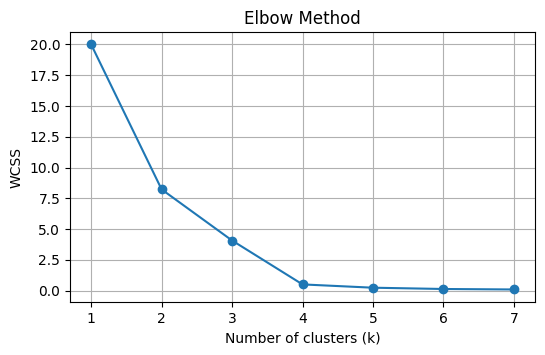

Customer  MonthlySpend_k  VisitFrequency  Cluster
      U4              55              12        0
      U5              58              14        0
      U6              52              11        0
      U1               8               2        1
      U3              12               2        1
      U2              10               3        1
      U7              25               8        2
      U8              28               7        2
      U9              30               9        2
     U10              65               3        3


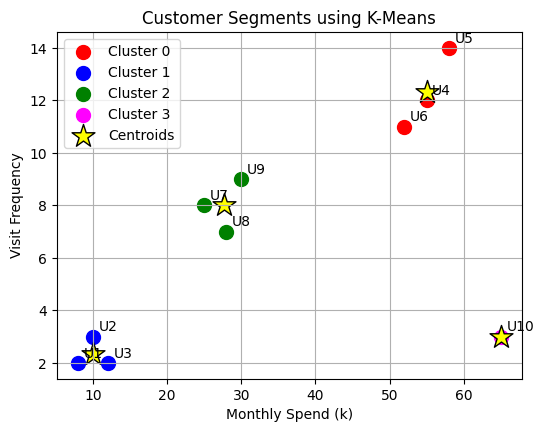

In [7]:
# Q7. K-Means - customer segmentation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


cust = pd.DataFrame({
    'Customer':['U1','U2','U3','U4','U5','U6','U7','U8','U9','U10'],
    'MonthlySpend_k':[8,10,12,55,58,52,25,28,30,65],
    'VisitFrequency':[2,3,2,12,14,11,8,7,9,3]})
print(cust, "\n")

Xc = cust[['MonthlySpend_k','VisitFrequency']]
Xc_s = StandardScaler().fit_transform(Xc)

# Elbow method
wcss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc_s).inertia_ for k in range(1, 8)]
plt.figure(figsize=(6,3.5))
plt.plot(range(1, 8), wcss, marker='o')
plt.title('Elbow Method'); plt.xlabel('Number of clusters (k)'); plt.ylabel('WCSS')
plt.grid(True); plt.show()

# Final clustering
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42)
cust['Cluster'] = km.fit_predict(Xc_s)
print(cust.sort_values('Cluster').to_string(index=False))

centers = StandardScaler().fit(Xc).inverse_transform(km.cluster_centers_)
plt.figure(figsize=(6,4.5))
colors = ['red','blue','green','magenta','cyan']
for c in range(K):
    sub = cust[cust.Cluster == c]
    plt.scatter(sub.MonthlySpend_k, sub.VisitFrequency, s=100, c=colors[c], label=f'Cluster {c}')
    for _, r in sub.iterrows():
        plt.annotate(r.Customer, (r.MonthlySpend_k, r.VisitFrequency), xytext=(4,4), textcoords='offset points')
plt.scatter(centers[:,0], centers[:,1], s=300, c='yellow', edgecolors='black', marker='*', label='Centroids')
plt.title('Customer Segments using K-Means')
plt.xlabel('Monthly Spend (k)'); plt.ylabel('Visit Frequency')
plt.legend(); plt.grid(True); plt.show()

In [8]:
# Q8. Naive Bayes - spam detection
import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB

mail = pd.DataFrame([
    ['M1',1,1,0,0,'Spam'],['M2',1,1,0,0,'Spam'],['M3',1,0,0,0,'Spam'],
    ['M4',0,1,0,0,'Spam'],['M5',0,0,1,1,'Ham'],['M6',0,0,1,1,'Ham'],
    ['M7',0,0,0,1,'Ham'],['M8',0,0,1,0,'Ham'],['M9',1,0,0,1,'Spam'],
    ['M10',0,1,1,0,'Spam'],['M11',0,0,1,1,'Ham'],['M12',0,0,0,1,'Ham']],
    columns=['Email ID','Offer','Prize','Schedule','Report','Class'])
print(mail, "\n")

words = ['Offer','Prize','Schedule','Report']
Xm = mail[words]
ym = mail['Class'].values

nb = MultinomialNB(alpha=1.0)          # Laplace smoothing
nb.fit(Xm, ym)
print("Classes:", nb.classes_, "| Priors:", np.exp(nb.class_log_prior_).round(3))
print("Training accuracy:", nb.score(Xm, ym))

# Classify a new email  (1 = word present, 0 = absent)
new_mail = pd.DataFrame([[1, 1, 0, 0]], columns=words)   # contains "Offer" and "Prize"
print("\nNew email features:", {w: int(v) for w, v in zip(words, new_mail.values[0])})
print("Predicted class:", nb.predict(new_mail)[0])
print("Probabilities  :", {str(c): round(float(p), 4) for c, p in zip(nb.classes_, nb.predict_proba(new_mail)[0])})

   Email ID  Offer  Prize  Schedule  Report Class
0        M1      1      1         0       0  Spam
1        M2      1      1         0       0  Spam
2        M3      1      0         0       0  Spam
3        M4      0      1         0       0  Spam
4        M5      0      0         1       1   Ham
5        M6      0      0         1       1   Ham
6        M7      0      0         0       1   Ham
7        M8      0      0         1       0   Ham
8        M9      1      0         0       1  Spam
9       M10      0      1         1       0  Spam
10      M11      0      0         1       1   Ham
11      M12      0      0         0       1   Ham 

Classes: ['Ham' 'Spam'] | Priors: [0.5 0.5]
Training accuracy: 1.0

New email features: {'Offer': 1, 'Prize': 1, 'Schedule': 0, 'Report': 0}
Predicted class: Spam
Probabilities  : {'Ham': 0.0443, 'Spam': 0.9557}


In [9]:
# Q9. Hidden Markov Model - Viterbi (weather)
import numpy as np
import pandas as pd

states = ['Sunny', 'Rainy']
obs_names = ['Cloudy', 'Rainy', 'Sunny']
obs_map = {o: i for i, o in enumerate(obs_names)}

start_p = np.array([0.5, 0.5])                 # Sunny, Rainy
trans_p = np.array([[0.6, 0.4],                # Sunny -> Sunny, Rainy
                    [0.3, 0.7]])               # Rainy -> Sunny, Rainy
emit_p  = np.array([[0.2, 0.1, 0.7],           # Sunny -> Cloudy, Rainy, Sunny
                    [0.3, 0.6, 0.1]])          # Rainy -> Cloudy, Rainy, Sunny

def run(observed):
    obs = [obs_map[o] for o in observed]
    path, V = viterbi(obs, start_p, trans_p, emit_p)
    print("Viterbi table (rows = time step, cols = Sunny, Rainy):")
    print(pd.DataFrame(V, columns=states, index=[f"t{i+1}: {o}" for i, o in enumerate(observed)]).round(6))
    print("\nObserved sequence :", observed)
    print("Hidden state path :", " -> ".join(states[s] for s in path))
    print("Probability of best path:", V[-1].max(), "\n")

def viterbi(obs, start_p, trans_p, emit_p):
    N, T = len(start_p), len(obs)
    V = np.zeros((T, N)); back = np.zeros((T, N), dtype=int)
    V[0] = start_p * emit_p[:, obs[0]]
    for t in range(1, T):
        for s in range(N):
            probs = V[t-1] * trans_p[:, s] * emit_p[s, obs[t]]
            back[t, s] = np.argmax(probs)
            V[t, s] = np.max(probs)
    path = [int(np.argmax(V[-1]))]
    for t in range(T - 1, 0, -1):
        path.insert(0, int(back[t, path[0]]))
    return path, V

# Sequence given in the question
print("### Sequence given in the question")
run(['Cloudy', 'Cloudy', 'Rainy', 'Sunny', 'Rainy', 'Cloudy'])

# Full 10-day sequence from the table (optional)
print("### Full 10-day table sequence")
run(['Cloudy','Cloudy','Rainy','Sunny','Rainy','Cloudy','Sunny','Sunny','Rainy','Cloudy'])

### Sequence given in the question
Viterbi table (rows = time step, cols = Sunny, Rainy):
               Sunny     Rainy
t1: Cloudy  0.100000  0.150000
t2: Cloudy  0.012000  0.031500
t3: Rainy   0.000945  0.013230
t4: Sunny   0.002778  0.000926
t5: Rainy   0.000167  0.000667
t6: Cloudy  0.000040  0.000140

Observed sequence : ['Cloudy', 'Cloudy', 'Rainy', 'Sunny', 'Rainy', 'Cloudy']
Hidden state path : Rainy -> Rainy -> Rainy -> Sunny -> Rainy -> Rainy
Probability of best path: 0.00014002631999999999 

### Full 10-day table sequence
Viterbi table (rows = time step, cols = Sunny, Rainy):
                Sunny     Rainy
t1: Cloudy   0.100000  0.150000
t2: Cloudy   0.012000  0.031500
t3: Rainy    0.000945  0.013230
t4: Sunny    0.002778  0.000926
t5: Rainy    0.000167  0.000667
t6: Cloudy   0.000040  0.000140
t7: Sunny    0.000029  0.000010
t8: Sunny    0.000012  0.000001
t9: Rainy    0.000001  0.000003
t10: Cloudy  0.000000  0.000001

Observed sequence : ['Cloudy', 'Cloudy', 'Rainy', 'Su